# Maaş Tahmini: Geliştirilmiş Model

`class.ipynb` içindeki **Linear Regression** modelinin skorunu geçmek için hazırlandı.
Karşılaştırmanın adil olması için **aynı veri** ve **aynı `train_test_split(test_size=0.2, random_state=42)`** kullanılıyor.

**Değerlendirme düzeni:**
1. Model seçimi sadece **eğitim verisinde**, çapraz doğrulamayla (GroupKFold) yapılıyor.
2. Seçilen model **test verisinde bir kez** ölçülüyor.

## 1. Kütüphaneler

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor, RandomForestRegressor, VotingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (LabelEncoder, OneHotEncoder, OrdinalEncoder,
                                   StandardScaler, TargetEncoder)

warnings.filterwarnings("ignore")

## 2. Ayarlar

In [2]:
DATA_PATH = "Salary_Data.csv"
TARGET = "Salary"
TEST_SIZE, RANDOM_STATE = 0.2, 42
CV = GroupKFold(n_splits=5)

EDUCATION_MAP = {"Bachelor's": "Bachelor's", "Bachelor's Degree": "Bachelor's",
                 "Master's": "Master's", "Master's Degree": "Master's",
                 "PhD": "PhD", "phD": "PhD", "High School": "High School"}
EDUCATION_ORDER = {"High School": 0, "Bachelor's": 1, "Master's": 2, "PhD": 3}
LEAD_PATTERN = "director|vp|chief|ceo|cto|head|principal|manager"
MIN_VALID_SALARY = 10_000   # 350, 500, 550, 579 $ gibi açıkça hatalı maaşlar (sadece eğitimden çıkarılır)

NUM_COLS = ["Age", "Years of Experience", "Start_Age", "Edu", "Senior", "Junior", "Lead"]

## 3. Yardımcı fonksiyonlar

In [3]:
def load_data(path):
    return pd.read_csv(path).dropna()


def baseline_features(raw):
    """class.ipynb'deki adımların birebir aynısı: LabelEncoder -> IQR -> Age sil."""
    df = raw.copy()
    for col in ["Gender", "Education Level", "Job Title"]:
        df[col] = LabelEncoder().fit_transform(df[col])
    q1, q3 = df[TARGET].quantile([0.25, 0.75])
    iqr = q3 - q1
    kept = df[(df[TARGET] > q1 - 1.5 * iqr) & (df[TARGET] < q3 + 1.5 * iqr)]
    removed = len(df) - len(kept)
    kept = kept.drop(columns=["Age"])
    return kept.drop(columns=[TARGET]), kept[TARGET], removed


def clean_data(raw):
    """Eğitim etiketlerini birleştirir, meslek adından kıdem bilgisi çıkarır."""
    df = raw.copy()
    df["Education Level"] = df["Education Level"].map(EDUCATION_MAP)
    df["Edu"] = df["Education Level"].map(EDUCATION_ORDER)
    df["Job Title"] = df["Job Title"].str.strip().str.replace("Juniour", "Junior")
    title = df["Job Title"].str.lower()
    df["Senior"] = title.str.contains("senior").astype(int)
    df["Junior"] = title.str.contains("junior").astype(int)
    df["Lead"] = title.str.contains(LEAD_PATTERN).astype(int)
    df["Start_Age"] = df["Age"] - df["Years of Experience"]   # işe başlama yaşı
    return df


def drop_invalid_salaries(X, y):
    """Hatalı maaşları SADECE eğitim verisinden çıkarır; test seti hiç değişmez."""
    keep = y >= MIN_VALID_SALARY
    return X[keep], y[keep]


def duplicate_groups(raw):
    """Birebir aynı satırlar aynı grup numarasını alır (GroupKFold için)."""
    return pd.Series(pd.factorize(raw.astype(str).agg("|".join, axis=1))[0], index=raw.index)


def target_encoding_prep():
    return ColumnTransformer([
        ("num", "passthrough", NUM_COLS),
        ("gender", OrdinalEncoder(), ["Gender"]),
        ("job", TargetEncoder(target_type="continuous", random_state=0), ["Job Title"]),
    ])


def extra_trees_prep():
    """Meslek iki şekilde kodlanır: ortalama maaşı (TargetEncoder) ve her meslek için 0/1 sütunu (OneHot)."""
    return ColumnTransformer([
        ("num", "passthrough", NUM_COLS),
        ("gender", OrdinalEncoder(), ["Gender"]),
        ("job_mean", TargetEncoder(target_type="continuous", random_state=0), ["Job Title"]),
        ("job_onehot", OneHotEncoder(handle_unknown="ignore"), ["Job Title"]),
    ])


def onehot_prep():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=3), ["Gender", "Job Title"]),
    ])


def build_candidates():
    rf = make_pipeline(target_encoding_prep(),
                       RandomForestRegressor(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE))
    gb = make_pipeline(target_encoding_prep(),
                       GradientBoostingRegressor(n_estimators=600, learning_rate=0.05, max_depth=5,
                                                 subsample=0.8, random_state=RANDOM_STATE))
    return {
        "RandomForest": rf,
        "GradientBoosting": gb,
        "Voting (RF + GB)": VotingRegressor([("rf", rf), ("gb", gb)]),
        "ExtraTrees": make_pipeline(extra_trees_prep(),
                                    ExtraTreesRegressor(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)),
    }


def regression_scores(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5}


def cv_r2(model, X, y, groups):
    return cross_val_score(model, X, y, cv=CV, groups=groups, scoring="r2").mean()

## 4. Veriyi yükle

In [4]:
raw = load_data(DATA_PATH)
groups = duplicate_groups(raw)
print(raw.shape)
raw.head()

(6698, 6)


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


## 5. Orijinal modeli birebir yeniden üret (baseline)
`class.ipynb` ile aynı adımlar: LabelEncoder → IQR → `Age` sil → split → StandardScaler → LinearRegression.

In [5]:
Xb, yb, removed = baseline_features(raw)
print("IQR ile silinen satır sayısı:", removed)

Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=TEST_SIZE, random_state=RANDOM_STATE)
baseline_model = make_pipeline(StandardScaler(), LinearRegression()).fit(Xb_train, yb_train)
baseline_pred = baseline_model.predict(Xb_test)

results = {"Orijinal LinearRegression": regression_scores(yb_test, baseline_pred)}
pd.DataFrame(results).T.round(4)

IQR ile silinen satır sayısı: 0


,R2,MAE,RMSE
Orijinal LinearRegression,0.6656,24447.6415,30880.7932


## 6. Orijinal modeldeki sorunlar

1. **`Education Level` aynı şeyi farklı yazıyor**: `Bachelor's` ve `Bachelor's Degree`, `Master's` ve `Master's Degree`, `PhD` ve `phD` ayrı sınıflar sayılıyor.
2. **LabelEncoder sahte bir sıralama uyduruyor**: `Job Title` alfabetik sırayla 0–190 arası sayılara çevrilmiş. Lineer model bu sayıları büyüklük gibi okuyor. Korelasyon tablosunda `Job Title`–`Salary` ilişkisinin 0.06 çıkmasının sebebi bu.
3. **IQR adımı hiçbir şey silmiyor**: Alt sınır negatif çıktığı için 350, 500 gibi hatalı maaşlar veride kalıyor (yukarıda 0 satır silindi).
4. **`Age` atılmış**: Ağaç tabanlı modeller için ek bilgi taşıyor.
5. **Lineer model etkileşimleri yakalayamıyor**: Meslek × deneyim × eğitim ilişkilerini düz bir doğru ifade edemez.

Bu yüzden: hatalı maaşları (10.000 $ altı) **sadece eğitim verisinden** çıkarıyorum. Test seti orijinaliyle birebir aynı kalıyor, yani karşılaştırma adil.

In [6]:
raw["Education Level"].value_counts()

Education Level
Bachelor's Degree    2265
Master's Degree      1572
PhD                  1368
Bachelor's            756
High School           448
Master's              288
phD                     1
Name: count, dtype: int64

## 7. Temizlik ve özellik mühendisliği

In [7]:
df = clean_data(raw)
df["Education Level"].value_counts()

Education Level
Bachelor's     3021
Master's       1860
PhD            1369
High School     448
Name: count, dtype: int64

## 8. Aynı split
Baseline ile **aynı satırlar** test setine düşsün diye aynı `test_size` ve `random_state` kullanılıyor.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(df, df[TARGET], test_size=TEST_SIZE, random_state=RANDOM_STATE)
assert X_test.index.equals(Xb_test.index), "test satırları baseline ile aynı olmalı"

n_before = len(X_train)
X_train, y_train = drop_invalid_salaries(X_train, y_train)
print("Eğitimden çıkarılan hatalı maaş satırı:", n_before - len(X_train))
print(X_train.shape, X_test.shape)

Eğitimden çıkarılan hatalı maaş satırı: 3
(5355, 11) (1340, 11)


## 9. Model seçimi: sadece eğitim verisinde çapraz doğrulama

Test verisine bakarak model seçersek test artık "hiç görülmemiş" veri olmaz. Bu yüzden adayları **sadece eğitim verisinde** karşılaştırıyorum:

- Eğitim verisi 5 parçaya bölünüyor. 4 parçayla eğitilip 1 parçayla deneniyor, bu 5 kez tekrarlanıyor (cross-validation).
- **GroupKFold** kullanıyorum: Veride çok sayıda birebir kopya satır var. Bir satırın kopyaları hep aynı parçaya düşüyor, böylece model doğrulama satırını eğitimde ezberlemiş olamıyor.

Adaylar: Random Forest, Gradient Boosting, ikisinin ortalaması (Voting) ve **ExtraTrees**. ExtraTrees, Random Forest'a benzer ama ağaçlardaki bölme noktalarını rastgele seçer; bu onu ezbere karşı biraz daha dayanıklı yapar. ExtraTrees'e mesleği iki şekilde veriyorum: o mesleğin ortalama maaşı (TargetEncoder) ve her meslek için ayrı 0/1 sütunu (OneHot).

In [9]:
candidates = build_candidates()
cv_scores = pd.Series({name: cv_r2(model, X_train, y_train, groups.loc[X_train.index])
                       for name, model in candidates.items()}, name="CV R2 (eğitim verisi)")
final_name = cv_scores.idxmax()
print(cv_scores.round(4))
print("\nSeçilen model:", final_name)

RandomForest        0.9055
GradientBoosting    0.9006
Voting (RF + GB)    0.9107
ExtraTrees          0.9227
Name: CV R2 (eğitim verisi), dtype: float64

Seçilen model: ExtraTrees


## 10. Test sonuçları (test verisine ilk ve tek bakış)

In [10]:
linear_onehot = make_pipeline(onehot_prep(), LinearRegression()).fit(X_train, y_train)
results["LinearRegression + temizlik + OneHot"] = regression_scores(y_test, linear_onehot.predict(X_test))

final_model = candidates[final_name].fit(X_train, y_train)
final_pred = final_model.predict(X_test)
results[f"FİNAL: {final_name}"] = regression_scores(y_test, final_pred)

pd.DataFrame(results).T.round({"R2": 4, "MAE": 0, "RMSE": 0})

,R2,MAE,RMSE
Orijinal LinearRegression,0.6656,24448.0,30881.0
LinearRegression + temizlik + OneHot,0.8389,15347.0,21430.0
FİNAL: ExtraTrees,0.9768,2760.0,8125.0


In [11]:
base, final = results["Orijinal LinearRegression"], results[f"FİNAL: {final_name}"]
print(f"R2  : {base['R2']:.4f}  ->  {final['R2']:.4f}")
print(f"MAE : {base['MAE']:,.0f} $  ->  {final['MAE']:,.0f} $   (%{100 * (1 - final['MAE'] / base['MAE']):.0f} daha az hata)")
print(f"RMSE: {base['RMSE']:,.0f} $  ->  {final['RMSE']:,.0f} $")

R2  : 0.6656  ->  0.9768
MAE : 24,448 $  ->  2,760 $   (%89 daha az hata)
RMSE: 30,881 $  ->  8,125 $


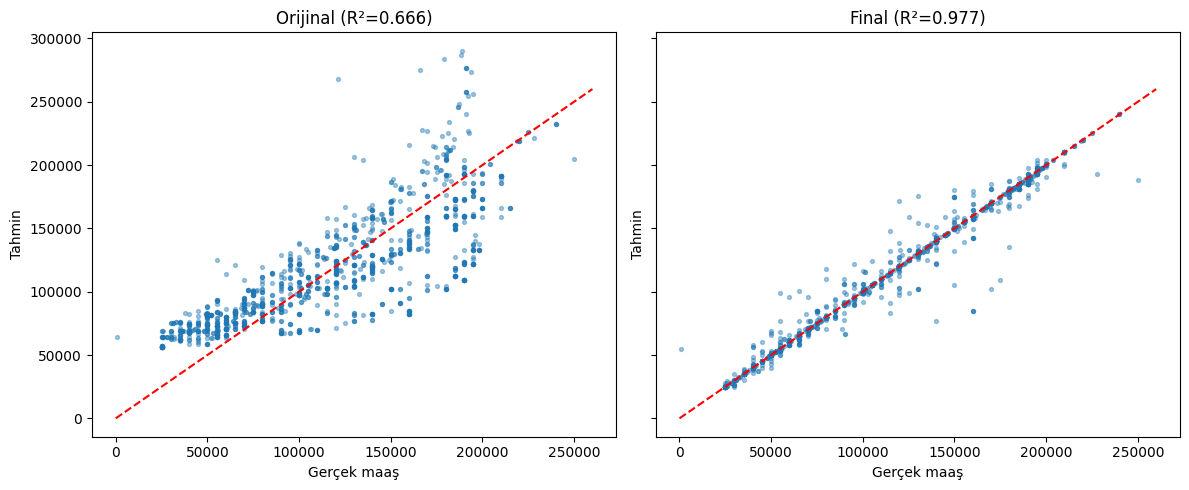

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, pred, title in [(axes[0], baseline_pred, f"Orijinal (R²={base['R2']:.3f})"),
                        (axes[1], final_pred, f"Final (R²={final['R2']:.3f})")]:
    ax.scatter(y_test, pred, s=8, alpha=0.4)
    ax.plot([0, 260000], [0, 260000], "r--")
    ax.set(title=title, xlabel="Gerçek maaş", ylabel="Tahmin")
plt.tight_layout(); plt.show()

## 11. Ek kontrol: bütün veride, kopyalar ayrı tutularak
Aynı GroupKFold testini bütün veri üzerinde orijinal ve final model için yapıyorum. Kopya satırların skoru şişirmediği bu şekilde de görülüyor.

In [13]:
print("Benzersiz satır:", groups.nunique(), "/", len(raw))
baseline_cv = cv_r2(make_pipeline(StandardScaler(), LinearRegression()), Xb, yb, groups.loc[Xb.index])
final_cv = cv_r2(build_candidates()[final_name], df, df[TARGET], groups)
print(f"GroupKFold R2   orijinal: {baseline_cv:.4f}   final: {final_cv:.4f}")

Benzersiz satır: 1787 / 6698


GroupKFold R2   orijinal: 0.6562   final: 0.9194


## 12. Model neye bakıyor? (özellik önemi)

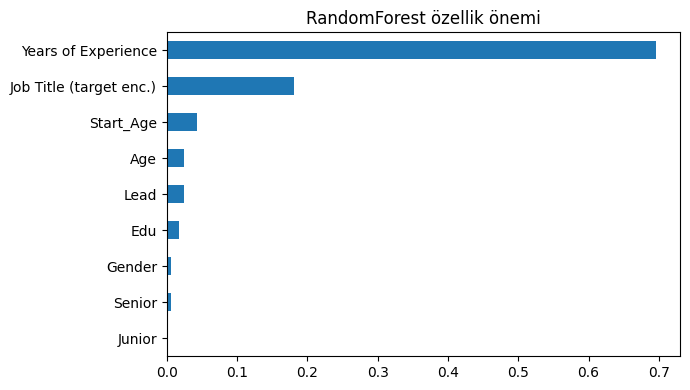

In [14]:
rf = build_candidates()["RandomForest"].fit(X_train, y_train)
importance = pd.Series(rf[-1].feature_importances_, index=NUM_COLS + ["Gender", "Job Title (target enc.)"])
importance.sort_values().plot.barh(figsize=(7, 4), title="RandomForest özellik önemi")
plt.tight_layout(); plt.show()

## 13. Sonuç
- Sadece **veri temizliği + doğru kodlama** (OneHot) ile lineer model bile 0.67'den ~0.84'e çıkıyor.
- **ExtraTrees + mesleğin iki şekilde kodlanması** ile test R² ~0.977'ye çıkıyor, ortalama hata ~24.000 $'dan ~2.800 $'a iniyor.
- Model seçimi test verisine bakılmadan, eğitim verisinde çapraz doğrulamayla yapıldı.
- Kopya satırlar ayrı tutulduğunda bile final model orijinalin çok üstünde kalıyor.